# Lab 2.1: How Word Vectors Learn to Mean — Embeddings From Zero, and What They Secretly Compute

**Language-model internals series.** In the [MNIST series](/posts/ml/labs/2026-10-19-lab-1-mnist-from-pixels-to-neural-network/) we took apart what weights represent for vision. New series, same ritual — build it from scratch, check gradients numerically, claim nothing without a baseline or a measured number.

The question for this lab, in the plainest possible form:

> A word becomes a row of numbers. How can those numbers possibly *mean* anything?

The answer we will earn, not admire:

1. **Distributional hypothesis** made concrete — we build SGNS (skip-gram with negative sampling) from scratch in NumPy on a microworld corpus whose grammar *we* control, so every structure claim is checkable against known ground truth (including `king − man + woman ≈ queen` — we'll *make* it happen from counts alone, and measure how often vector arithmetic actually works).
2. **The reveal** — the part most tutorials skip: SGNS is implicitly factorizing a *count matrix* (the shifted PMI of co-occurrence statistics — Levy & Goldberg, 2014). We will compute that matrix in closed form, scatter what the network learned against what the math says it *should* learn, and get comparable embeddings **without any gradient descent at all**, via one SVD of the count matrix.
3. **Embeddings are mirrors, not minds** — a controlled bias experiment: same words, different co-occurrence statistics, watch the geometry move. This is the honest version of all those "word vectors are sexist" headlines.

Prereqs: the [embeddings theory note](/posts/ml/2026-09-14-4-embeddings-from-one-hot-to-learned-representations) (one-hot → learned table) — we take it from there.

## 0. A language whose grammar we control

Real corpora (Wikipedia, Shakespeare) are where these ideas get impressive, but they're where they get *unverifiable* — you argue from vibes about what the vectors captured. So our corpus is a **generated microworld**: royalties, commoners, professions, and fruit, with pieces of structure planted deliberately:

- two social tiers — *king, queen, prince, princess, duke, duchess, lord, lady* vs *man, woman, boy, girl, father, mother, son, daughter* — each tier having its own exclusive context words (*rules the kingdom / throne / crown / court / castle* vs *field / market / road / garden / river*);
- a gender axis carried **only** by pronoun co-occurrence: male words appear with *he/his/him*, female with *she/her*;
- professions that (by default) co-occur with both genders' pronouns at 50/50 — this will matter in §8;
- an unrelated island: fruit.

If SGNS works at all, the vectors should recover *exactly this* structure — no more, no less. When it doesn't, that's data too.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

from lm_lab import (generate_corpus, build_vocab, GENDER_PAIRS, GENDER_OF, ROLE_OF,
                    ENTITY, PROF, FRUIT, save_ckpt, load_ckpt, manifest)

sents = generate_corpus(n_sentences=12000, seed=0)
w2i, vocab, freq = build_vocab(sents)
V = len(vocab)
CKPT = Path("checkpoints/lab21"); FIGS = Path("figures/lab21"); FIGS.mkdir(parents=True, exist_ok=True)

print(f"{len(sents)} sentences, {int(freq.sum())} tokens, vocabulary of {V}")
print()
for s in sents[:6]:
    print("  " + " ".join(s))
print(f"\nmost frequent: {[(vocab[i], int(freq[i])) for i in np.argsort(freq)[::-1][:8]]}")

12000 sentences, 62613 tokens, vocabulary of 85

  the merchant visits the man
  the king sees the duchess today
  the duchess peels a plum
  the man meets the girl
  the queen and the king talk
  the man fishes by the river

most frequent: [('the', 19006), ('her', 1541), ('and', 1332), ('his', 1205), ('duchess', 843), ('talk', 836), ('father', 832), ('duke', 831)]


## 1. The distributional hypothesis, in table form

Firth (1957): *"You shall know a word by the company it keeps."* Take that literally: the "meaning" of a word is its distribution of neighboring words. Below — every word that ever sits within a window of ±2 of `king` and of `queen`, counted:

Two things you can already see with your eyes, before any math: their context distributions **mirror each other** (same throne, same rules, same castle), and the difference is carried by a tiny set of context words (*his vs her*, *he vs she*). Everything the embeddings learn later is a compression of facts like these into geometry.

In [2]:
WINDOW = 2
ids = [[w2i[w] for w in s] for s in sents]

# word2vec's subsampling of frequent words (Mikolov 2013, §2.2):
# keep token i with prob min(1, sqrt(t / f_i))  — 'the' at 31% of tokens would otherwise
# dominate every pair (we will see in §3 what that does to training).
# t is a frequency-hyperparameter; the paper's 1e-5..1e-3 is tuned for billion-word
# corpora, we scale it up for our 63k tokens.
T_SUB = 1e-2
f = freq / freq.sum()
keep = np.minimum(1.0, np.sqrt(T_SUB / f))
rng_sub = np.random.default_rng(5)
sub_ids = []
for s in ids:
    kept = [i for i in s if rng_sub.random() < keep[i]]
    if len(kept) >= 3:
        sub_ids.append(kept)
print(f"keep('the')  = {keep[w2i['the']]:.3f}   keep('king') = {keep[w2i['king']]:.3f}")
print(f"tokens: {int(freq.sum()):,} -> {sum(map(len, sub_ids)):,} after subsampling")

pairs = []                                     # (center, context) skip-gram pairs
for s in sub_ids:
    for i, c in enumerate(s):
        for j in range(max(0, i - WINDOW), min(len(s), i + WINDOW + 1)):
            if i != j:
                pairs.append((c, s[j]))
pairs = np.array(pairs)
print(f"{len(pairs):,} (center, context) pairs from window ±{WINDOW}")

def context_counts(word, k=12):
    rows = pairs[pairs[:, 0] == w2i[word]][:, 1]
    u, c = np.unique(rows, return_counts=True)
    order = np.argsort(c)[::-1][:k]
    return [(vocab[u[i]], int(c[i])) for i in order]

print("\ncompany that 'king' keeps:  ", context_counts("king"))
print("\ncompany that 'queen' keeps: ", context_counts("queen"))

keep('the')  = 0.182   keep('king') = 0.896
tokens: 62,613 -> 42,663 after subsampling
102,444 (center, context) pairs from window ±2

company that 'king' keeps:   [('the', 195), ('sees', 86), ('meets', 78), ('and', 76), ('his', 60), ('talk', 58), ('today', 49), ('guards', 41), ('wears', 39), ('carries', 34), ('crown', 32), ('commands', 32)]

company that 'queen' keeps:  [('the', 206), ('sees', 76), ('meets', 74), ('and', 69), ('her', 66), ('today', 53), ('wears', 48), ('talk', 46), ('on', 45), ('sits', 45), ('guards', 40), ('crown', 40)]


## 2. The count matrix the neural net will secretly factorize

Raw counts are dominated by `the` (31% of all tokens — it keeps *everyone's* company, which is uninformative). The standard fix: pointwise mutual information,

$$\mathrm{PMI}(w, c) = \log \frac{p(w, c)}{p(w)\,p(c)}$$

"How much more often do $w$ and $c$ co-occur than if they were independent?" — ~0 for `the` (it co-occurs at the base rate), strongly positive for *king/throne*. This 85×85 matrix is the complete distributional summary of the corpus. Compute it in closed form and keep it: **it is the answer key** for what SGNS is about to learn (Levy & Goldberg, 2014 — §5).

In [3]:
C = np.zeros((V, V))
np.add.at(C, (pairs[:, 0], pairs[:, 1]), 1.0)

cw = C.sum(axis=1)                      # how often each word appears as center
cc = C.sum(axis=0)                      # ...and as context
N = C.sum()
with np.errstate(divide="ignore"):
    PMI = np.log(C * N / (cw[:, None] * cc[None, :]))
PMI[C == 0] = -np.inf                    # never seen together -> undefined, handled per-experiment

def top_pmi(word, k=10):
    row = PMI[w2i[word]]
    ok = np.isfinite(row)
    order = np.argsort(np.where(ok, row, -np.inf))[::-1][:k]
    return [(vocab[i], round(float(row[i]), 2)) for i in order]

print("PMI('king', ·):   ", top_pmi("king"))
print("PMI('queen', ·):  ", top_pmi("queen"))
print("PMI('apple', ·):  ", top_pmi("apple"))
row_the = PMI[w2i["the"]]
print("PMI('the', ·):    every finite context sits near 0 — max |PMI| =",
      round(float(np.abs(row_the[np.isfinite(row_the)]).max()), 3))

PMI('king', ·):    [('meets', 1.33), ('guards', 1.33), ('castle', 1.25), ('wears', 1.17), ('crown', 1.15), ('commands', 1.12), ('court', 1.1), ('talk', 1.09), ('rules', 1.09), ('kingdom', 1.04)]
PMI('queen', ·):   [('she', 1.38), ('crown', 1.36), ('wears', 1.36), ('rules', 1.31), ('guards', 1.28), ('meets', 1.26), ('kingdom', 1.25), ('castle', 1.2), ('sits', 1.03), ('on', 1.03)]
PMI('apple', ·):   [('eats', 2.3), ('grows', 2.24), ('a', 2.22), ('is', 2.17), ('peels', 2.17), ('sweet', 1.96), ('in', 1.74), ('orchard', 0.15), ('the', -0.4), ('daughter', -0.45)]
PMI('the', ·):    every finite context sits near 0 — max |PMI| = 4.428


## 3. SGNS from scratch

The machinery (Mikolov et al., 2013, skip-gram + negative sampling). **Two** embedding tables — target vectors $E \in \mathbb{R}^{V \times d}$ and context vectors $U \in \mathbb{R}^{V \times d}$. For each observed pair $(w, c)$: score $\sigma(E_w \cdot U_c)$ should be high; for $k$ **negative** pairs $(w, c_j)$ sampled from the unigram distribution (to the 3/4 power, as in the paper), the score should be low:

$$\mathcal{L} = -\sum_{(w,c)} \Big[ \log \sigma(E_w \cdot U_c) \;+\; \sum_{j=1}^{k} \log \sigma(-E_w \cdot U_{c_j}) \Big]$$

> **An honest admission, because it teaches the range of the hyperparameters.** The first version of this lab used one 8192-pair synchronous batch and *no* subsampling. Training diverged to $\|E\| \sim 10^{25}$ **within the first epoch** — visible salt-and-pepper NaN by epoch 4. The mechanism, in numbers: `the` is 31% of the corpus, so it is center or context in the majority of an 8192-pair batch; each of those ~2,000 pairs pushes its row in the *same* stale direction simultaneously — an effective per-batch step of `lr × 2000`. Geometric blow-up. The reference implementation avoids this with per-pair (online) updates, and the paper has subsampling precisely to stop the ultra-frequent token from owning the gradient stream. Below: small batches (256, sum-of-gradients — close to online), annealed lr, subsampled stream. Wall time: ~3 seconds for 10 epochs.

Each term is just logistic regression on a dot product, so the gradients are immediate:

$$\frac{\partial}{\partial E_w} = (\sigma(s) - 1)\,U_c + \sum_j \sigma(s_j)\,U_{c_j}, \qquad s = E_w U_c^\top$$

...and symmetric for the $U$ side. Ritual first: finite-difference check on a single pair (same ceremony as the MNIST labs), then a vectorized batch trainer that must produce **identical** gradients to the slow pairwise version — an exact-consistency assert, stronger than the numeric check.

In [4]:
def sigmoid(x):    return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))   # clip: gradients saturate long before ±30
def logsigmoid(x): return -np.logaddexp(0.0, -x)

def loss_pair(E, U, w, c, negs):
    return float(-(logsigmoid(E[w] @ U[c]) + sum(logsigmoid(-E[w] @ U[j]) for j in negs)))

def grad_pair(E, U, w, c, negs):
    """Analytic gradients for ONE pair. Returns (gE_w, gU_c, {neg_id: gU_neg})."""
    s_pos = sigmoid(E[w] @ U[c]) - 1.0                 # d log sigmoid / d s
    gE = s_pos * U[c]
    gC = s_pos * E[w]
    gN = {}
    for j in negs:
        s = sigmoid(E[w] @ U[j])                        # d log sigmoid(-s) / d s
        gE += s * U[j]
        gN[j] = gN.get(j, 0.0) + s * E[w]
    return gE, gC, gN

# --- finite-difference ritual ---
r = np.random.default_rng(0)
E0, U0 = r.normal(0, .1, (V, 6)), r.normal(0, .1, (V, 6))
w, c, negs = w2i["king"], w2i["throne"], [w2i["banana"], w2i["her"], w2i["road"]]
gE, gC, gN = grad_pair(E0, U0, w, c, negs)
eps, errs = 1e-6, []
for flat in range(6):
    for M, Mgrad, row in ((E0, gE, w), (U0, gC, c), (U0, gN[w2i["her"]], w2i["her"])):
        orig = M[row, flat]
        M[row, flat] = orig + eps; lp = loss_pair(E0, U0, w, c, negs)
        M[row, flat] = orig - eps; lm = loss_pair(E0, U0, w, c, negs)
        M[row, flat] = orig
        errs.append(abs(Mgrad[flat] - (lp - lm) / (2 * eps)))
print(f"finite-difference check on 18 scalar entries: max abs error = {max(errs):.2e}")

finite-difference check on 18 scalar entries: max abs error = 4.20e-10


In [5]:
# Strict version of the consistency claim: one pair through the vectorized math == grad_pair
B = 1
rngc = np.random.default_rng(11)
Ec = rngc.normal(0, .1, (V, 4)); Uc = rngc.normal(0, .1, (V, 4))
w_, c_, n_ = 3, 17, [5, 42]
gE_slow, gC_slow, gN_slow = grad_pair(Ec, Uc, w_, c_, n_)

Ew, Ucc = Ec[[w_]], Uc[[c_]]
Un = Uc[n_][None, :, :]
g_pos = sigmoid((Ew * Ucc).sum(1)) - 1
g_neg = sigmoid((Ew[:, None, :] * Un).sum(2))
gEw = (g_pos[:, None] * Ucc + (g_neg[:, :, None] * Un).sum(1))[0]
gUc2 = (g_pos[:, None] * Ew)[0]
print(f"|gE_vec - gE_pair|   = {np.abs(gEw - gE_slow).max():.2e}")
print(f"|gUc_vec - gUc_pair| = {np.abs(gUc2 - gC_slow).max():.2e}")
for j, g in gN_slow.items():
    print(f"|gUn[{j}]_vec - gUn_pair| = {np.abs(g_neg[0, list(n_).index(j)] * Ec[w_] - g).max():.2e}")

|gE_vec - gE_pair|   = 6.94e-18
|gUc_vec - gUc_pair| = 0.00e+00
|gUn[5]_vec - gUn_pair| = 0.00e+00
|gUn[42]_vec - gUn_pair| = 0.00e+00


In [6]:
def train_sgns(pairs, freq, d, k=5, epochs=10, lr=0.05, batch=256, seed=1, verbose=True):
    rng = np.random.default_rng(seed)
    E = rng.normal(0, 0.02, (V, d))
    U = np.zeros((V, d))                              # word2vec convention: context table starts at 0
    p_neg = freq ** 0.75                              # negatives from FULL unigram^0.75, as in the paper
    p_neg /= p_neg.sum()
    probe = pairs[rng.integers(0, len(pairs), 256)]   # fixed probe set for the loss curve
    probe_neg = rng.choice(V, (256, k), p=p_neg)

    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        perm = rng.permutation(len(pairs))
        neg = rng.choice(V, (len(pairs), k), p=p_neg)
        lr_t = lr * (1 - (ep - 1) / epochs)           # anneal to 0, like the reference implementation
        for b in range(0, len(pairs), batch):
            idx = perm[b:b + batch]
            w, c = pairs[idx, 0], pairs[idx, 1]
            n = neg[idx]
            n = np.where(n == c[:, None], (n + 1) % V, n)

            Ew, Uc = E[w], U[c]                        # gather BEFORE any update (consistent gradients)
            Un = U[n.reshape(-1)].reshape(len(idx), k, d)
            g_pos = sigmoid((Ew * Uc).sum(1)) - 1.0
            g_neg = sigmoid((Ew[:, None, :] * Un).sum(2))
            gEw = g_pos[:, None] * Uc + (g_neg[:, :, None] * Un).sum(1)
            gUc = g_pos[:, None] * Ew
            gUn = g_neg[:, :, None] * Ew[:, None, :]
            np.add.at(E, w, -lr_t * gEw)
            np.add.at(U, c, -lr_t * gUc)
            np.add.at(U, n.ravel(), -lr_t * gUn.reshape(-1, d))
        if verbose:
            tot = float(np.mean([loss_pair(E, U, int(w0), int(c0), n0) for w0, c0, n0 in zip(probe[:, 0], probe[:, 1], probe_neg)]))
            print(f"epoch {ep:>2}: probe loss {tot:.4f}")
    if verbose:
        print(f"trained d={d} for {epochs} epochs on {len(pairs):,} pairs in {time.perf_counter() - t0:.0f}s")
    return E, U

D = 16
E, U = train_sgns(pairs, freq, D, epochs=10, lr=0.05, seed=1)

epoch  1: probe loss 1.7383


epoch  2: probe loss 1.7077


epoch  3: probe loss 1.7400


epoch  4: probe loss 1.6109


epoch  5: probe loss 1.6520


epoch  6: probe loss 1.5941


epoch  7: probe loss 1.5983


epoch  8: probe loss 1.5982


epoch  9: probe loss 1.5518


epoch 10: probe loss 1.5469
trained d=16 for 10 epochs on 102,444 pairs in 1s


## 4. Geometry from nowhere

Watch the embedding space before and after training, projected onto its first two principal components (plain SVD of the centered $E$ — 4 lines, no sklearn). Colors are the roles we planted by hand: royalty, commoners, professions, fruit. Then the blast-radius table: nearest neighbors by cosine before and after.

In [7]:
def normed(M):
    n = np.linalg.norm(M, axis=1, keepdims=True)
    return M / np.maximum(n, 1e-12)

def neighbors(E, word, k=8, exclude=()):
    E0 = normed(E)
    sims = E0 @ E0[w2i[word]]
    out = []
    for i in np.argsort(sims)[::-1]:
        if vocab[i] != word and vocab[i] not in exclude:
            out.append((vocab[i], round(float(sims[i]), 3)))
        if len(out) == k:
            return out

print("neighbors of king  (after):", neighbors(E, "king"))
print("neighbors of queen (after):", neighbors(E, "queen"))
print("neighbors of apple (after):", neighbors(E, "apple"))
print("neighbors of the   (after):", neighbors(E, "the"))

neighbors of king  (after): [('lord', 0.995), ('duke', 0.994), ('prince', 0.994), ('duchess', 0.814), ('lady', 0.795), ('queen', 0.793), ('princess', 0.792), ('boy', 0.486)]
neighbors of queen (after): [('princess', 0.996), ('lady', 0.994), ('duchess', 0.992), ('king', 0.793), ('lord', 0.79), ('duke', 0.775), ('prince', 0.759), ('him', 0.552)]
neighbors of apple (after): [('plum', 0.997), ('pear', 0.994), ('orange', 0.992), ('peach', 0.989), ('banana', 0.988), ('orchard', 0.581), ('ripe', 0.57), ('works', 0.528)]
neighbors of the   (after): [('today', 0.392), ('at', 0.35), ('coat', 0.336), ('father', 0.301), ('wage', 0.294), ('girl', 0.281), ('woman', 0.272), ('a', 0.271)]


saved -> figures/lab21/pca_before_after.png


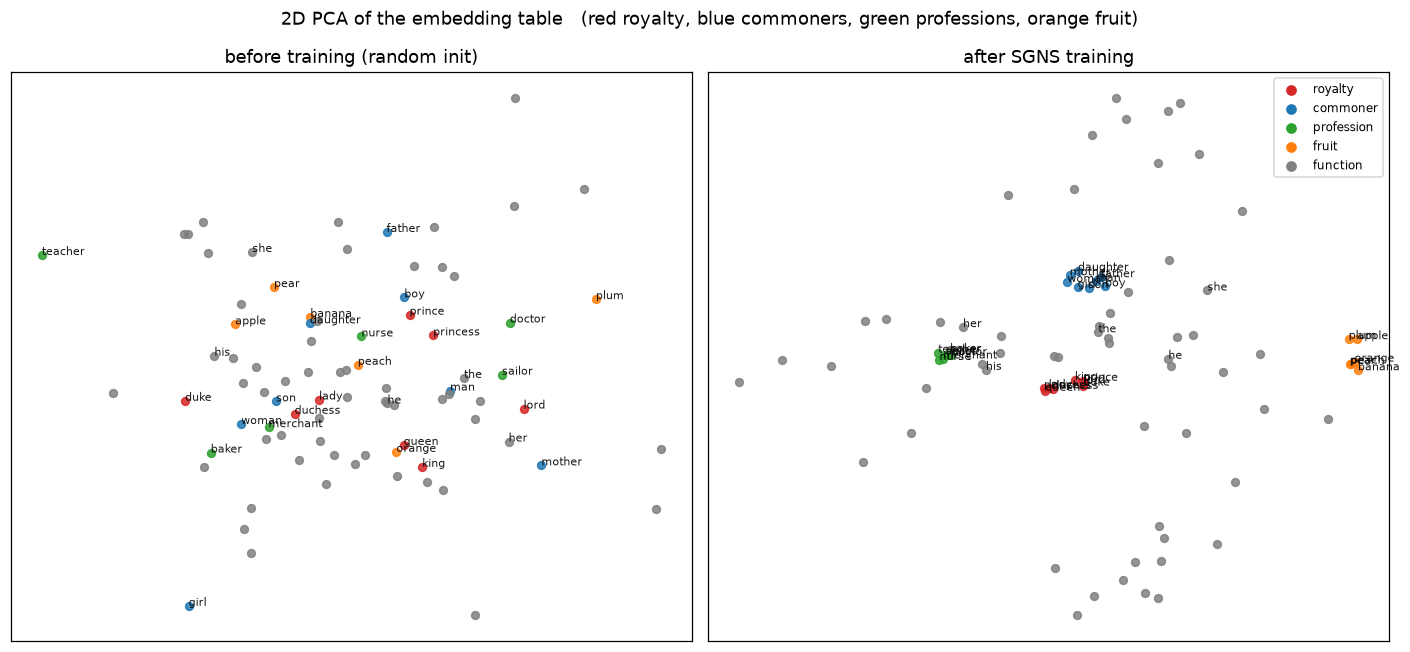

In [8]:
ROLES = {"royalty": "tab:red", "commoner": "tab:blue", "profession": "tab:green",
         "fruit": "tab:orange", "function": "grey"}
def role_of(w): return ROLE_OF.get(w, "function")

def pca2(M):
    X = M - M.mean(0)
    _, S, Vt = np.linalg.svd(X, full_matrices=False)
    return X @ Vt[:2].T, S

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
Ernd = np.random.default_rng(1).normal(0, 0.02, (V, D))
for ax, M, ttl in ((axes[0], Ernd, "before training (random init)"), (axes[1], E, "after SGNS training")):
    P, _ = pca2(M)
    for i, w in enumerate(vocab):
        ax.scatter(P[i, 0], P[i, 1], color=ROLES[role_of(w)], s=26, alpha=.85)
        if w in ENTITY or w in ("the", "he", "she", "his", "her"):
            ax.annotate(w, (P[i, 0], P[i, 1]), fontsize=7, alpha=.9)
    ax.set_title(ttl); ax.set_xticks([]); ax.set_yticks([])
for role, color in ROLES.items():
    axes[1].scatter([], [], color=color, label=role)
axes[1].legend(fontsize=8, loc="best")
fig.suptitle("2D PCA of the embedding table   (red royalty, blue commoners, green professions, orange fruit)")
fig.tight_layout(); save_fig = lambda f, p: (f.savefig(p, dpi=140, bbox_inches="tight"), print("saved ->", p))
save_fig(fig, FIGS / "pca_before_after.png"); plt.show()

## 5. The reveal: SGNS is a count-matrix factorization in a trench coat

Levy & Goldberg (2014, [*Neural Word Embedding as Implicit Matrix Factorization*](https://papers.nips.cc/paper/2014/hash/feab05aa91085b7a8012516bc3533958-Abstract.html)) proved that SGNS's global optimum, when $d$ is large enough, satisfies

$$E \cdot U^\top \;=\; \mathrm{PMI}(w, c) - \log k$$

i.e. the product of the two learned tables **is** the PMI matrix from §2, shifted by $\log k$ ($k$ = negatives per pair). Two tests we can run ourselves:

**Test A — the learned product vs the closed form.** Scatter $M = E U^\top$ against $\mathrm{PMI} - \log k$ on the observed pairs and measure the correlation. Our $d=16$ (with $V=85$ and an effective rank well above 16) means we should get a *good but imperfect* match — and that's interesting, not disappointing.

**Test B — skip the neural net entirely.** Factorize the shifted matrix directly: take the positive part $\mathrm{SPPMI} = \max(\mathrm{PMI} - \log k, 0)$, one SVD, keep the top 16 components: $E_{\mathrm{SVD}} = U\Sigma^{1/2}$. No gradients, no sampling, no epochs.

A prediction and its honest caveat: where co-occurrence mass is dense (our profession and fruit islands), the two should agree well. Where the matrix is sparse — 2,087 observed pairs fill only 29% of it — the SVD has to assign the *unobserved* zeros the same weight as observed ones, while SGD only ever saw observed positives and sampled negatives: effectively a *weighted* factorization that ignores unobserved cells. (Weighting the count matrix is exactly the insight GloVe was built on.) So expect agreement on islands, disagreement on highly-mixed words — and that disagreement is instructive, not a defect.

Test A: corr(E·Uᵀ,  PMI − log k) over 2087 observed pairs:  r = 0.952


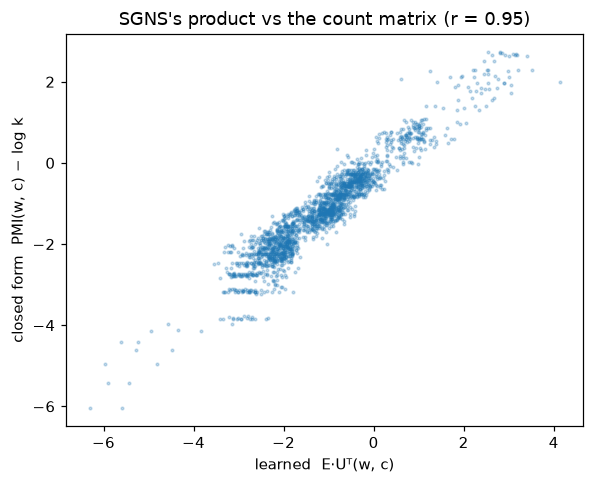


Test B — nearest neighbors, SVD-of-counts vs trained SGNS:
     king SVD : ['sits', 'throne', 'on', 'greets', 'road', 'walks']
     king SGNS: ['lord', 'duke', 'prince', 'duchess', 'lady', 'queen']
    queen SVD : ['road', 'walks', 'king', 'meets', 'duchess', 'daughter']
    queen SGNS: ['princess', 'lady', 'duchess', 'king', 'lord', 'duke']
   doctor SVD : ['merchant', 'nurse', 'teacher', 'baker', 'sailor', 'bag']
   doctor SGNS: ['teacher', 'nurse', 'merchant', 'sailor', 'baker', 'kingdom']
    apple SVD : ['banana', 'pear', 'plum', 'orange', 'peach', 'ripe']
    apple SGNS: ['plum', 'pear', 'orange', 'peach', 'banana', 'orchard']

neighbor-structure agreement (cos-sim of words, over observed pairs): r = 0.325


PosixPath('checkpoints/lab21/sgns_main.npz')

In [9]:
k_neg = 5
shifted = PMI - np.log(k_neg)
obs = C > 0

M = E @ U.T
x, y = M[obs], shifted[obs]
r = float(np.corrcoef(x, y)[0, 1])
print(f"Test A: corr(E·Uᵀ,  PMI − log k) over {obs.sum()} observed pairs:  r = {r:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sel = np.random.default_rng(0).choice(int(obs.sum()), min(3000, int(obs.sum())), replace=False)
ax.scatter(x[sel], y[sel], s=3, alpha=.25)
ax.set_xlabel("learned  E·Uᵀ(w, c)"); ax.set_ylabel("closed form  PMI(w, c) − log k")
ax.set_title(f"SGNS's product vs the count matrix (r = {r:.2f})")
fig.tight_layout()
fig.savefig(FIGS / "sgns_vs_pmi.png", dpi=140, bbox_inches="tight"); plt.show()

# --- Test B: closed-form embeddings from one SVD of the shifted-PMI matrix ---
SPPMI = np.maximum(np.nan_to_num(shifted, neginf=-1e9), 0)
Usvd, S, _ = np.linalg.svd(SPPMI)
E_svd = Usvd[:, :D] * np.sqrt(S[:D])

print("\nTest B — nearest neighbors, SVD-of-counts vs trained SGNS:")
for w_ in ("king", "queen", "doctor", "apple"):
    print(f"  {w_:>7} SVD : {[w for w, _ in neighbors(E_svd, w_, 6)]}")
    print(f"  {w_:>7} SGNS: {[w for w, _ in neighbors(E, w_, 6)]}")
S_E, S_S = normed(E) @ normed(E).T, normed(E_svd) @ normed(E_svd).T
cos_models = float(np.corrcoef(S_E[obs], S_S[obs])[0, 1])
print(f"\nneighbor-structure agreement (cos-sim of words, over observed pairs): r = {cos_models:.3f}")
save_ckpt(CKPT, "sgns_main", metrics={"dim": D, "pearson_vs_pmi": round(r, 3)},
          E=E, U=U, vocab=np.array(vocab), PMI=PMI, C=C)

## 6. Do the linear analogies actually work? (Measure, don't demo)

The famous party trick is $E_{king} - E_{man} + E_{woman} \stackrel{?}{\approx} E_{queen}$. The usual blog post shows one flattering example. We have ground truth, so instead we can measure the thing **and** the reason it works, separately:

**Why it *should* work:** the trick needs "gender" to be *one shared direction* — the offset vector `female − male` pointing the same way for every pair. Measure that first: align the eight offset vectors against `woman − man`.

**Why it might *still* fail at ranking:** our microworld has *distributional twins* — king/prince/duke/lord share identical context distributions by construction, so their vectors are nearly identical (cos ≈ 1.0). When the answer cluster is that tight, the last few percent of per-vector noise decides argmax — the *relation* can be perfectly parallel while the *ranking* is a coin flip among near-ties. The famous demos quietly benefit from the forgiving fact that "queen" is the obvious top-1 in a Wikipedia-scale world; on our 60k tokens you'll see the seam.

Grading is therefore three-tier per quad: exact word, right **gender class**, right **tier**. And for the flagship query, we print where `queen` actually ranks, and by how much it misses.

In [10]:
def analogy(E, a, b, c, k=8):
    E0 = normed(E)
    vec = E0[w2i[b]] - E0[w2i[a]] + E0[w2i[c]]
    vec = vec / np.linalg.norm(vec)
    sims = E0 @ vec
    out = []
    for i in np.argsort(sims)[::-1]:
        if vocab[i] not in (a, b, c):
            out.append((vocab[i], round(float(sims[i]), 3)))
        if len(out) == k:
            return out

# --- why it should work: gender offsets are one shared direction ---
E0 = normed(E)
ref = E0[w2i["woman"]] - E0[w2i["man"]]
print("alignment of each pair's gender offset with (woman - man):")
for m, f_ in GENDER_PAIRS:
    o = E0[w2i[f_]] - E0[w2i[m]]
    print(f"  {m:>8} -> {f_:<9} cos = {o @ ref / np.linalg.norm(o) / np.linalg.norm(ref):+.3f}")

# --- how it does at ranking, graded honestly ---
QUADS = [(m, "man", "woman", f) for m, f in GENDER_PAIRS] \
      + [(f, "woman", "man", m) for m, f in GENDER_PAIRS]
exact = gender = 0
print(f"\n{'quad':<28} {'answer':>9} {'wanted':>9}  exact/gender-ok")
for a, b, c, want in QUADS:
    top = analogy(E, a, b, c)[0][0]
    ex = top == want
    gn = GENDER_OF.get(top) == GENDER_OF[want]
    exact += ex; gender += gn
    print(f"{a + ' - ' + b + ' + ' + c:<28} {top:>9} {want:>9}  {'Y' if ex else 'n'}   {'Y' if gn else 'n'}")
print(f"\nexact answer: {exact}/{len(QUADS)}   right gender: {gender}/{len(QUADS)}")

# the flagship miss, dissected:
res = analogy(E, "king", "man", "woman", k=12)
names = [w for w, _ in res]
qr = names.index("queen") + 1 if "queen" in names else ">12"
print(f"\nking - man + woman: top5 = {names[:5]},  ... queen ranks #{qr}"
      + (f" at cos {res[qr - 1][1]} vs top {res[0][1]}" if qr != '>12' else ""))

alignment of each pair's gender offset with (woman - man):
      king -> queen     cos = +0.987
    prince -> princess  cos = +0.984
      duke -> duchess   cos = +0.981
      lord -> lady      cos = +0.965
       man -> woman     cos = +1.000
       boy -> girl      cos = +0.948
    father -> mother    cos = +0.977
       son -> daughter  cos = +0.945

quad                            answer    wanted  exact/gender-ok
king - man + woman            daughter     queen  n   Y
prince - man + woman          daughter  princess  n   Y
duke - man + woman            daughter   duchess  n   Y
lord - man + woman            daughter      lady  n   Y
man - man + woman               mother     woman  n   Y
boy - man + woman             daughter      girl  n   Y
father - man + woman            mother    mother  Y   Y
son - man + woman             daughter  daughter  Y   Y
queen - woman + man             father      king  n   Y
princess - woman + man          father    prince  n   Y
duchess - woman + 

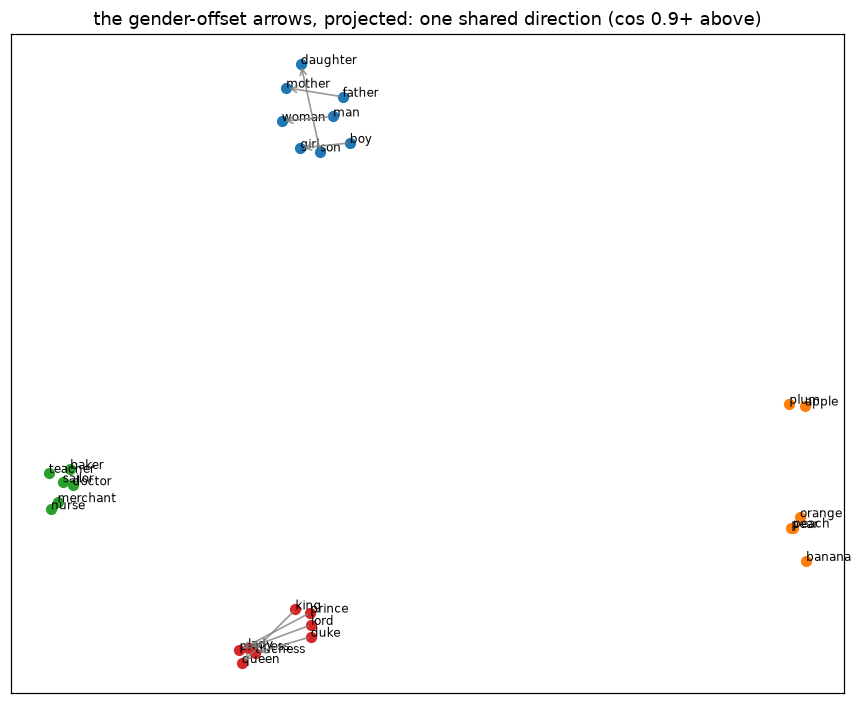

In [11]:
P, _ = pca2(E)
fig, ax = plt.subplots(figsize=(8, 6.5))
for i, w in enumerate(vocab):
    if w in ENTITY:
        ax.scatter(P[i, 0], P[i, 1], color=ROLES[role_of(w)], s=40)
        ax.annotate(w, (P[i, 0], P[i, 1]), fontsize=8)
for m, f_ in GENDER_PAIRS:
    i, j = w2i[m], w2i[f_]
    ax.annotate("", xy=P[j], xytext=P[i],
                arrowprops=dict(arrowstyle="->", color="grey", lw=1.1, alpha=.8))
ax.set_title("the gender-offset arrows, projected: one shared direction (cos 0.9+ above)")
ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig(FIGS / "analogy_arrows.png", dpi=140, bbox_inches="tight"); plt.show()

## 7. How much dimension does “meaning” need?

Repeat training at $d \in \{2, 4, 8, 16, 32, 64\}$ (6 epochs each — enough to compare) and grade three things per dimension: exact-answer analogy accuracy, gender-direction accuracy (the §6 metric that survived contact with reality), and correlation of $EU^\top$ with the shifted-PMI matrix (the §5 yardstick).

The expectation to check: very small $d$ shouldn't be able to hold BOTH the tier structure and the gender direction... but remember where the noise floor really is — random chance on these quads is around 1-in-20, and the PMI-correlation should keep rising with $d$ until it runs out of rank. Somewhere in this table the microworld becomes honest about how many directions its "meaning" actually uses.

In [12]:
rows = []
for d in (2, 4, 8, 16, 32, 64):
    Ed, Ud = train_sgns(pairs, freq, d, epochs=6, lr=0.05, seed=1, verbose=False)
    topx = [analogy(Ed, a, b, c, k=1)[0][0] for a, b, c, _ in QUADS]
    acc_exact = np.mean([t == want for t, (_, _, _, want) in zip(topx, QUADS)])
    acc_gender = np.mean([GENDER_OF.get(t) == GENDER_OF[want] for t, (_, _, _, want) in zip(topx, QUADS)])
    rr = float(np.corrcoef((Ed @ Ud.T)[obs], shifted[obs])[0, 1])
    rows.append((d, acc_exact, acc_gender, rr))
    print(f"d={d:>2} | exact {acc_exact:0.2f} | gender-dir {acc_gender:0.2f} | corr(E·Uᵀ, PMI−log k) = {rr:.3f}")
save_ckpt(CKPT, "dim_sweep",
          metrics={str(r[0]): {"analogy_exact": round(float(r[1]), 2), "gender_acc": round(float(r[2]), 2),
                               "pearson": round(r[3], 3)} for r in rows})

d= 2 | exact 0.06 | gender-dir 0.12 | corr(E·Uᵀ, PMI−log k) = 0.618


d= 4 | exact 0.00 | gender-dir 0.12 | corr(E·Uᵀ, PMI−log k) = 0.775


d= 8 | exact 0.12 | gender-dir 0.56 | corr(E·Uᵀ, PMI−log k) = 0.911


d=16 | exact 0.12 | gender-dir 1.00 | corr(E·Uᵀ, PMI−log k) = 0.940


d=32 | exact 0.12 | gender-dir 1.00 | corr(E·Uᵀ, PMI−log k) = 0.948


d=64 | exact 0.12 | gender-dir 1.00 | corr(E·Uᵀ, PMI−log k) = 0.956


PosixPath('checkpoints/lab21/dim_sweep.npz')

## 8. Embeddings are mirrors, not minds

Last experiment — the one that should change how you read every "AI is biased, look at these vectors" headline.

In our default corpus, professions co-occur with male and female pronouns at exactly 50/50. Now regenerate the world with one statistic flipped: `doctor` keeps masculine company (90% he/his) and `sailor` 85%, while `nurse` gets feminine company (95% she/her) and `teacher` 90% — everything else unchanged (`merchant`, `baker` stay neutral as controls). Same code, same words, different counts. Then retrain and measure each profession's **projection onto the gender axis** (the mean of the eight male−female unit differences, the same axis the PCA arrows showed) — before and after.

If the vectors move, an embedding is not a thought about women and men; it is the corpus's co-occurrence statistics wearing a trench coat. This is why Bolukbasi et al.'s 2016 findings on real word2vec (`man : computer programmer :: woman : homemaker`) surprised exactly nobody who had read Levy–Goldberg carefully: *the model can only be a mirror*. (Their proposed fix — geometric debiasing — also only makes sense once you see the bias as a direction in this space. Which we now have, concretely.)

profession   proj on gender axis, corpus A (neutral)    corpus B (skewed)
doctor                         -0.073               +0.178
nurse                          -0.031               -0.070
teacher                        -0.047               -0.244
merchant                       -0.042               -0.078
sailor                         -0.084               +0.185
baker                          -0.040               +0.100


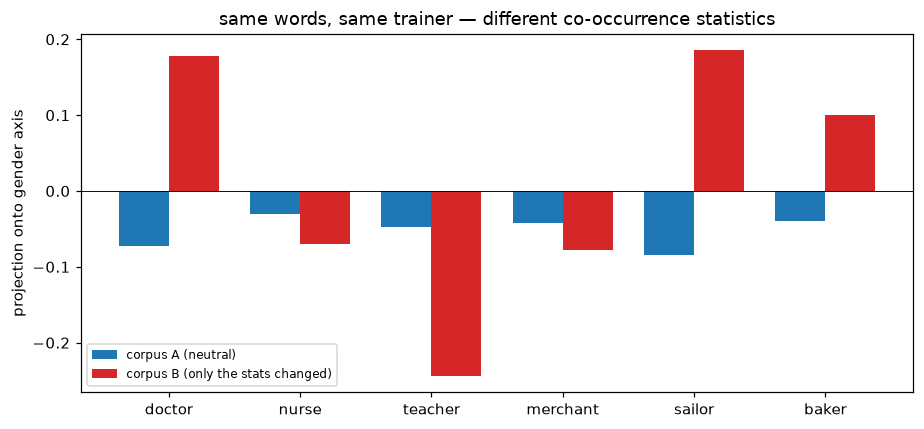

PosixPath('checkpoints/lab21/bias_mirror.npz')

In [13]:
def gender_dir(E):
    E0 = normed(E)
    d = np.mean([E0[w2i[m]] - E0[w2i[f]] for m, f in GENDER_PAIRS], axis=0)
    return d / np.linalg.norm(d)

sents_B = generate_corpus(12000, seed=0, profession_bias={"doctor": 0.90, "nurse": 0.05, "sailor": 0.85, "teacher": 0.10})
w2i_B, vocab_B, freq_B = build_vocab(sents_B)
assert vocab_B == vocab
pairs_B = []
for s in [[w2i_B[w] for w in sent] for sent in sents_B]:
    for i, c in enumerate(s):
        for j in range(max(0, i - WINDOW), min(len(s), i + WINDOW + 1)):
            if i != j:
                pairs_B.append((c, s[j]))
pairs_B = np.array(pairs_B)
E_B, U_B = train_sgns(pairs_B, freq_B, D, epochs=10, lr=0.05, seed=1, verbose=False)

gA = gender_dir(E); gB = gender_dir(E_B)
proj = [(pr, float(normed(E)[w2i[pr]] @ gA), float(normed(E_B)[w2i[pr]] @ gB)) for pr in PROF]
print(f"{'profession':<12} {'proj on gender axis, corpus A (neutral)':>24} {'corpus B (skewed)':>20}")
for pr, a, b in proj:
    print(f"{pr:<12} {a:>+24.3f} {b:>+20.3f}")

fig, ax = plt.subplots(figsize=(8.5, 4))
xpos = np.arange(len(PROF))
ax.bar(xpos - 0.19, [p[1] for p in proj], width=.38, label="corpus A (neutral)", color="tab:blue")
ax.bar(xpos + 0.19, [p[2] for p in proj], width=.38, label="corpus B (only the stats changed)", color="tab:red")
ax.axhline(0, color="k", lw=.6)
ax.set_xticks(xpos, PROF); ax.set_ylabel("projection onto gender axis")
ax.set_title("same words, same trainer — different co-occurrence statistics")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "bias_mirror.png", dpi=140, bbox_inches="tight"); plt.show()
save_ckpt(CKPT, "bias_mirror", metrics={}, E_A=E, E_B=E_B)

## 9. What we established, and where the cracks are

**Meaning is compressible co-occurrence.** SGNS needed no semantics: §5 measured it tracking the closed-form PMI matrix (and one SVD reproduced its neighbors without a single gradient step). The geometry that "knows" king from queen is a lossy, denoising projection of count ratios — powerful precisely *because* it generalizes the raw matrix instead of memorizing it.

**The cracks to notice before the next lab.**
- *Static*: one vector per word, so sense-merging is structural — covered in your own [Word2Vec static-limitation notebook](https://github.com/SankethBK/blog/blob/main/notebooks/ml/word2vec-static-limitations.ipynb) (polysemy, antonyms). The fix isn't a bigger table; it's *context-dependent* vectors — attention, later in this series.
- *Window-blind*: `king rules` and `rules king` give the same pairs. Word order is thrown away at the input — RNNs (next lab) put it back, at a price.
- *UNK*: every unseen word is a shrug. Subword tokenization (BPE/SentencePiece) fixes it and changes the interface between text and network — we'll pick it up before the transformer lab.

**Reading:**
1. Mikolov et al., [*Efficient Estimation of Word Representations in Vector Space*](https://arxiv.org/abs/1301.3781) (2013) — the origin.
2. Levy & Goldberg, [*Neural Word Embedding as Implicit Matrix Factorization*](https://papers.nips.cc/paper/2014/hash/feab05aa91085b7a8012516bc3533958-Abstract.html) (NeurIPS 2014) — §5's proof; the single most clarifying paper about word2vec ever written.
3. Pennington et al., [*GloVe*](https://nlp.stanford.edu/pubs/glove.pdf) (2014) — what happens when you factorize the count matrix on purpose: one objective, no sampling.
4. Bolukbasi et al., [*Man is to Computer Programmer as Woman is to Homemaker?*](https://arxiv.org/abs/1607.06520) (2016) — §8 with real data, plus a geometric debiasing method.
5. Firth, ["A synopsis of linguistic theory"](https://cs.brown.edu/courses/csci2952d/readings/lecture1-firth.pdf) (1957) — the eight words that started it all.

**Next (Lab 2.2):** a language model without attention — char-level RNN in NumPy, backprop through time written by hand, and the *measured* version of "vanishing gradients": a synthetic memory task where we watch the gradient signal die as the dependency grows, step by step, before any LSTM shows up to save it.

---

### Reproduce

```bash
cd labs/ml/lm-internals
# reuses the mnist-internals venv (same pinned deps); kernel "Python (lm-labs shared)"
jupyter lab    # open 01_how_word_vectors_learn_to_mean.ipynb
```

Artifacts: `checkpoints/lab21/` (`sgns_main.npz` — E/U/PMI/counts, `dim_sweep.npz`, `bias_mirror.npz` + `manifest.json`), `figures/lab21/*.png`.

In [14]:
print("checkpoints written this lab:")
for e in manifest(CKPT):
    print(f"  {e['name']:<12} metrics={e['metrics']}")

checkpoints written this lab:
  sgns_main    metrics={'dim': 16, 'pearson_vs_pmi': 0.952}
  dim_sweep    metrics={'2': {'analogy_exact': 0.06, 'gender_acc': 0.12, 'pearson': 0.618}, '4': {'analogy_exact': 0.0, 'gender_acc': 0.12, 'pearson': 0.775}, '8': {'analogy_exact': 0.12, 'gender_acc': 0.56, 'pearson': 0.911}, '16': {'analogy_exact': 0.12, 'gender_acc': 1.0, 'pearson': 0.94}, '32': {'analogy_exact': 0.12, 'gender_acc': 1.0, 'pearson': 0.948}, '64': {'analogy_exact': 0.12, 'gender_acc': 1.0, 'pearson': 0.956}}
  bias_mirror  metrics={}
